# PID controller

The PID control equation for the process value $u$ you should try using at time $t$ is given by 

$$
u(t) = P\cdot e(t) + I\cdot \int_0^t e(t')dt' + D\cdot\frac{de}{dt}
$$

where $P$ is the proportional term, $I$ is the integral term, and $D$ is the derivative term. Another way to think about this is that $P$ gives you the present behavior, $I$ gives the historical/past behavior, and $D$ tries to predict the future. 

The $P$, $I$, and $D$ constants are also called "gains," and each term essentially tells the PID control equation how sensitive it should be to the present, past, and future information. Turn any of these off by setting its gain value to 0. 

$e(t)$ is the error term, which reports the difference between your process and your reference (or desired) value.

## Intuition

The Proportional response operates by returning a value that is big if your error is big, and small if the error is small. The problem is that $P$ will tend to overshoot unless you compute the equation at a much higher rate than your process can change. 

The Integral response sums the past errors, which is very important since often we have very small steady-state errors (like constant drift) that we do not notice at any given time, but which compound over time to become significant. If $I$ is too large, then small changes over a short time can have exaggerated effects. If $I$ is too small, then it takes forever for the PID to respond to errors. 

The Derivative term estimates the rate of change of errors (it is sometimes called "anticipatory control" and reduces overshoot. $D$ can not correct for steady-state errors (like constant drift). 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class Robot(object):
    def __init__(self, length=20.0, tolerance=1.e-4, max_steering_angle=np.pi / 4.0):
        """
        Creates robot and initializes location/orientation to 0, 0, 0.
        """
        self.tolerance = tolerance
        self.max_steering_angle = max_steering_angle 
        self.x = 0.0 # initial starting position in x
        self.y = 0.0 # initial starting position in y
        self.v = 0.0 # initial scalar speed (velocity is self.v,self.orientation)
        self.orientation = 0.0 # heading angle of the bike
        self.length = length
        self.steering_noise = 0.0
        self.speed_noise = 0.0
        self.steering_drift = 0.0

    def set(self, x, y, v, orientation):
        """
        Sets a robot coordinate.
        """
        self.x = x
        self.y = y
        self.v = v
        self.orientation = orientation % (2.0 * np.pi)

    def set_noise(self, steering_noise, speed_noise):
        """
        Sets the noise parameters. We pass the stdev of the Gaussian distribution
        for steering and distance (really it is speed)
        """
        # makes it possible to change the noise parameters
        # this is often useful in particle filters
        self.steering_noise = steering_noise
        self.speed_noise = speed_noise

    def set_steering_drift(self, drift):
        """
        Sets the asystematical steering drift, like if your steering is misaligned
        """
        self.steering_drift = drift

    def move(self, steering, dt):
        """
        steering = front wheel steering angle, limited by max_steering_angle
        dt = total time duration of this movement. Must be non-negative
        """
        steering = np.clip(steering, -self.max_steering_angle, self.max_steering_angle)
        distance = self.v * dt
        
        # apply noise. This is the random noise that life throws at us, like an uneven road,
        # twitchy hands, maybe a pothole. I'm approximating it for now as a random number
        # chosen from a Gaussian (or Normal) distribution function. Most of the time, it 
        # will be very small, and rarely it will be 2-3 times the noise value. 
        steering2 = np.random.normal(steering, self.steering_noise)
        distance2 = np.random.normal(distance, self.speed_noise*np.sqrt(dt))

        # apply steering drift
        steering2 += self.steering_drift

        # Execute motion
        turn = np.tan(steering2) * distance2 / self.length

        if np.abs(turn) < self.tolerance:
            # approximate by straight line motion
            self.x += distance2 * np.cos(self.orientation)
            self.y += distance2 * np.sin(self.orientation)
            self.orientation = (self.orientation + turn) % (2.0 * np.pi)
        else:
            # approximate bicycle model for motion
            radius = distance2 / turn
            cx = self.x - (np.sin(self.orientation) * radius)
            cy = self.y + (np.cos(self.orientation) * radius)
            self.orientation = (self.orientation + turn) % (2.0 * np.pi)
            self.x = cx + (np.sin(self.orientation) * radius)
            self.y = cy - (np.cos(self.orientation) * radius)

    def __repr__(self):
        return '[x=%.5f y=%.5f v=%.5f orient=%.5f]' % (self.x, self.y, self.v, self.orientation)


In [29]:
def simulation(robot, P, I, D, n=200, dt=1.0):
    """
    Creates a 2-d trajectory of a robot. This uses the bicycle model, where the rear wheel is fixed and the front one steers (up to a
    maximum angle). 

    The 'cte' in the code is the "cross-track error." In this particular simulation, we expect the robot to follow y=0 so
    the robot.y value is also its positional (y) error. The PIP equation is providing us with the updated control variable
    of the steering angle based on the cross-track (y) error over time. 

    Arguments:
        robot: instance of the Robot class
        P: Float, controls importance of proportionality
        I: Float, controls importance of integral
        D: Float, controls importance of derivative
        n: Integer, number of steps the robot should take.
        dt: Float, how many seconds pass per timestep.

    Returns:
        x, y: np arrays of the 2d path taken by the robot.

    """
    t, x, y = [], [], []
    control = []
    integral = 0.0
    cte = robot.y
    for i in range(n):
        diff = (robot.y - cte) / dt
        cte = robot.y
        integral += cte
        steer = (-P * cte) - (D * diff) - (I * integral)
        robot.move(steer, dt)
        t.append(dt)
        x.append(robot.x)
        y.append(robot.y)
        control.append(steer)
    return np.cumsum(t), np.asarray(x), np.asarray(y), np.asarray(control)

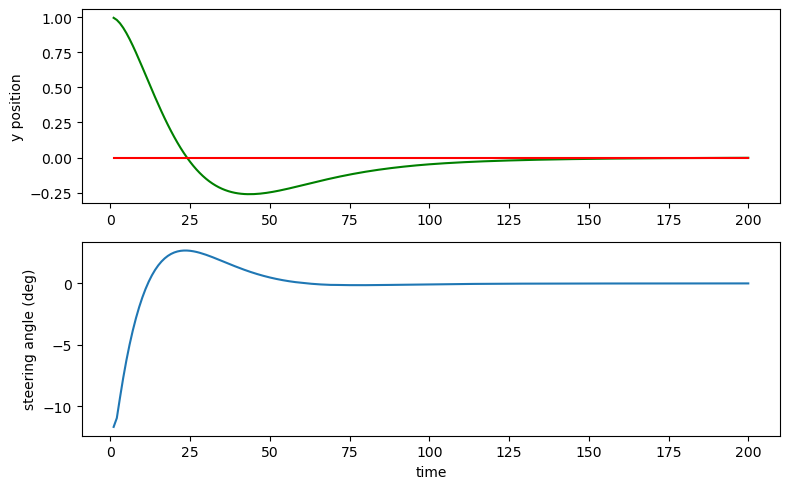

In [38]:
robot = Robot()
robot.set(x=0, y=1, v=1, orientation=0)

t, x, y, steering = simulation(robot, P=0.2, I=0.004, D=3.0, n=200, dt=1)
n = len(x)

fig, ax = plt.subplots(2, 1, figsize=(8,5))
ax[0].plot(x, y, 'g', label='PID controller')
ax[0].plot(x, np.zeros(n), 'r', label='reference')
ax[0].set_ylabel('y position')
ax[1].plot(t, np.degrees(steering))
ax[1].set_xlabel('time')
ax[1].set_ylabel('steering angle (deg)')
plt.tight_layout()
plt.show()

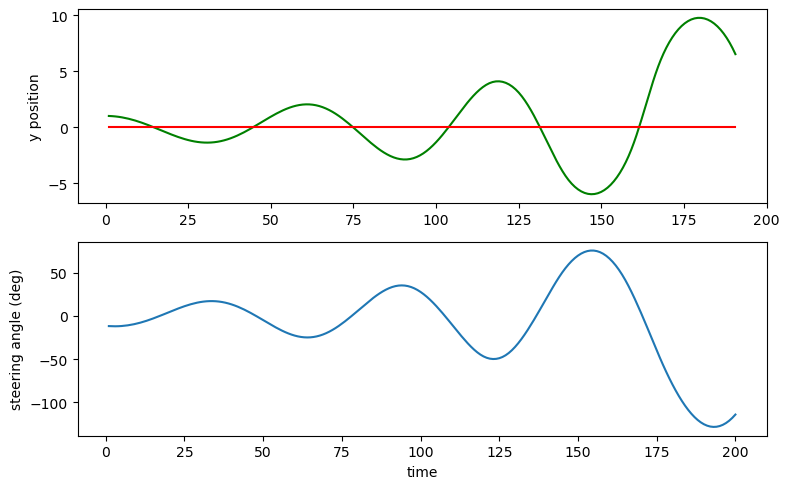

In [39]:
# What if we turn off the Derivative?
robot = Robot()
robot.set(x=0, y=1, v=1, orientation=0)

t, x, y, steering = simulation(robot, P=0.2, I=0.004, D=0, n=200, dt=1)
n = len(x)

fig, ax = plt.subplots(2, 1, figsize=(8,5))
ax[0].plot(x, y, 'g', label='PID controller')
ax[0].plot(x, np.zeros(n), 'r', label='reference')
ax[0].set_ylabel('y position')
ax[1].plot(t, np.degrees(steering))
ax[1].set_xlabel('time')
ax[1].set_ylabel('steering angle (deg)')
plt.tight_layout()
plt.show()

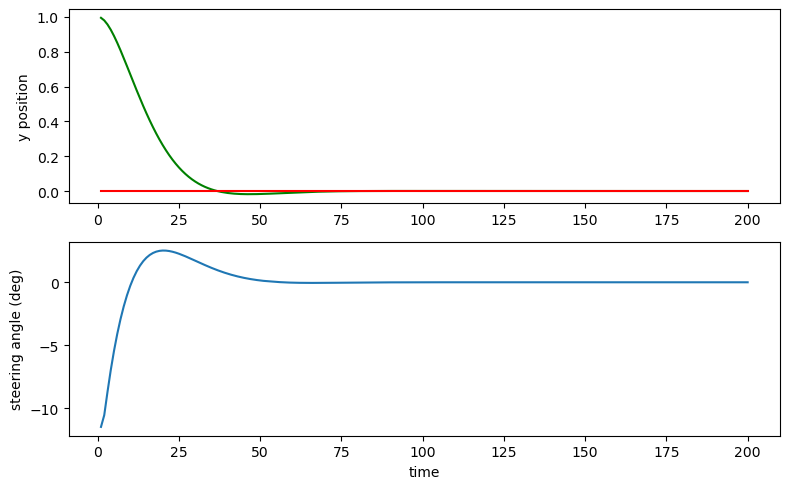

In [40]:
# What if we turn off the Integral?
robot = Robot()
robot.set(x=0, y=1, v=1, orientation=0)

t, x, y, steering = simulation(robot, P=0.2, I=0.00, D=3, n=200, dt=1)
n = len(x)

fig, ax = plt.subplots(2, 1, figsize=(8,5))
ax[0].plot(x, y, 'g', label='PID controller')
ax[0].plot(x, np.zeros(n), 'r', label='reference')
ax[0].set_ylabel('y position')
ax[1].plot(t, np.degrees(steering))
ax[1].set_xlabel('time')
ax[1].set_ylabel('steering angle (deg)')
plt.tight_layout()
plt.show()

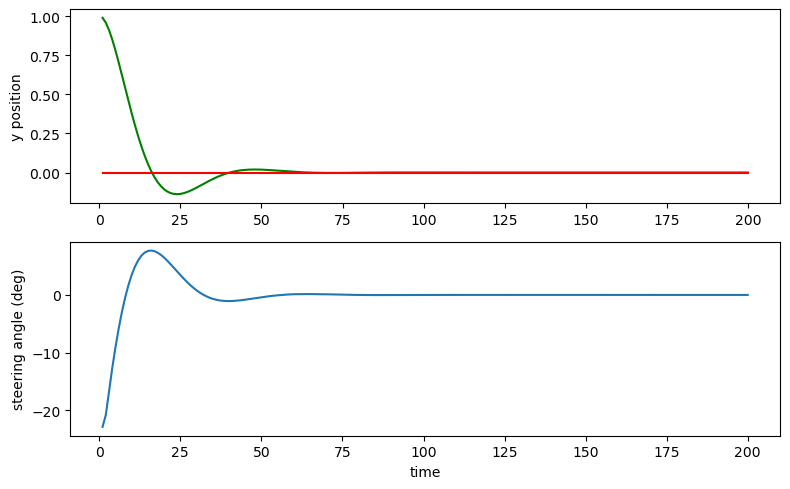

In [41]:
# What if we increase P?
robot = Robot()
robot.set(x=0, y=1, v=1, orientation=0)

t, x, y, steering = simulation(robot, P=0.4, I=0.00, D=3, n=200, dt=1)
n = len(x)

fig, ax = plt.subplots(2, 1, figsize=(8,5))
ax[0].plot(x, y, 'g', label='PID controller')
ax[0].plot(x, np.zeros(n), 'r', label='reference')
ax[0].set_ylabel('y position')
ax[1].plot(t, np.degrees(steering))
ax[1].set_xlabel('time')
ax[1].set_ylabel('steering angle (deg)')
plt.tight_layout()
plt.show()

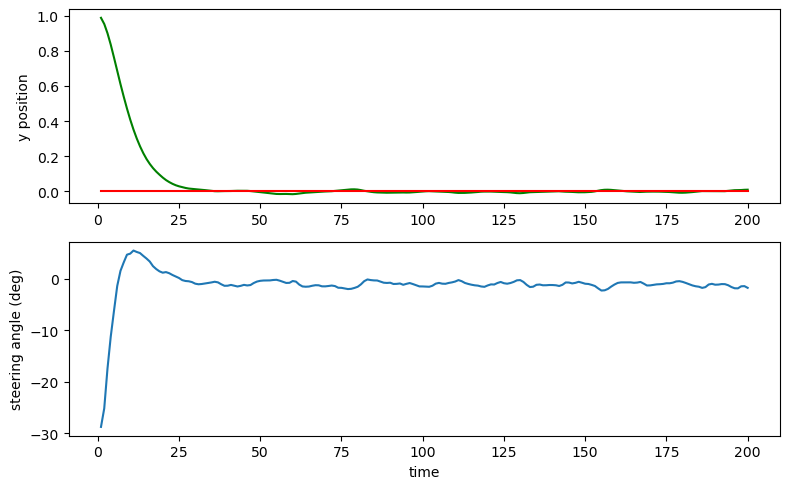

In [69]:
# tinker around
robot = Robot()
robot.set(x=0, y=1, v=1, orientation=0)
robot.set_noise(np.radians(1),0.01)
robot.set_steering_drift(np.radians(1))

t, x, y, steering = simulation(robot, P=0.5, I=2.e-3, D=5, n=200, dt=1)
n = len(x)

fig, ax = plt.subplots(2, 1, figsize=(8,5))
ax[0].plot(x, y, 'g', label='PID controller')
ax[0].plot(x, np.zeros(n), 'r', label='reference')
ax[0].set_ylabel('y position')
ax[1].plot(t, np.degrees(steering))
ax[1].set_xlabel('time')
ax[1].set_ylabel('steering angle (deg)')
plt.tight_layout()
plt.show()

In [50]:
class PIDmove():
    def __init__(self,P, I, D, distance=30, dt=0.01, nmax=200, tolerance=1):
        """
        Creates a 2-d trajectory of a robot. This uses the bicycle model, where the rear wheel is fixed and the front one steers (up to a
        maximum angle). 
    
        In this case we fix the steering angle and vary the velocity to move a fixed distance
        """
        self.robot = Robot()
        self.robot.set(x=0, y=0, v=0, orientation=np.pi/2)

        self.P, self.I, self.D = P, I, D
        self.distance = distance
        self.nmax = nmax
        self.dt = dt
        self.tolerance = 1

        self.integral = 0
        self.diff = 0
        self.t, self.output = [],[]

    def error(self):
        return np.abs(self.robot.y - self.distance)

    def move(self,v):
        self.robot.v = v
        self.robot.move(0,self.dt)

    def __call__(self): # run w/o a stopping criteria to see what happens

        self.t.append(0)
        self.output.append([self.robot.x, self.robot.y, self.robot.v, self.error()])

        for i in range(self.nmax):
            error_now = self.error()
            if i==0:
                self.error_prev = error_now
            self.diff = (error_now - self.error_prev) / self.dt
            self.integral += error_now * self.dt
            self.error_prev = error_now + 0. 
            
            control = (self.P * error_now) + (self.D * self.diff) + (self.I * self.integral)
            self.move(control)

            self.t.append(self.dt)
            self.output.append([self.robot.x, self.robot.y, self.robot.v, error_now])
        return np.cumsum(self.t), np.asarray(self.output)

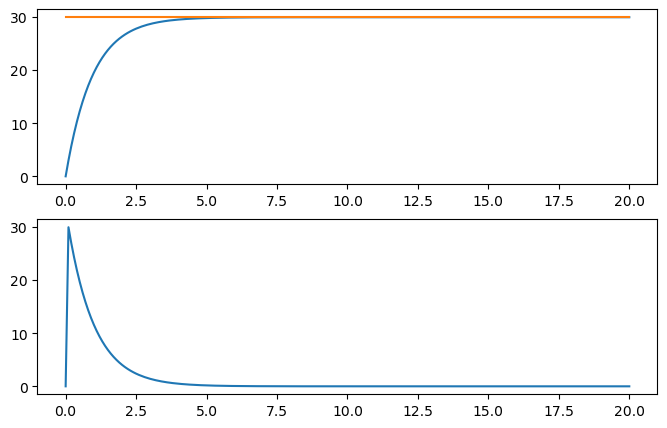

In [70]:
r = PIDmove(1,0,0,nmax=200,dt=0.1)
t,output = r()
fig, ax = plt.subplots(2, 1, figsize=(8,5))
ax[0].plot(t,output[:,1])
ax[0].plot(t,np.ones_like(t)*30)
ax[1].plot(t,output[:,2])

In [49]:
output

array([[1.8369702e-15, 3.0000000e+01, 3.0000000e+02, 3.0000000e+01],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+01, 0.0000000e+00, 0.0000000e+00],
       [1.8369702e-15, 3.0000000e+

In [48]:
r.robot.v

0.0

In [215]:
alpha=np.radians(27.5)
d=6.25
l=16
p=7.5
H=80
def theta_approx(D):
    return np.degrees(
        np.arctan2(H-p-l*np.cos(np.radians(48)+alpha),
                      D+d+l*np.sin(np.radians(48)+alpha)))
theta_approx(42) 

47.058782036848896

In [84]:
np.sin(np.radians(30)+alpha)*l

13.418729087126783

In [216]:
D0 = 42
theta0 = np.radians(48)
def dtheta(delta):
    # inches away from D0 starting point
    bigH = (H-p)/l
    bigD = (D0+delta+d)/l
    q = theta0+alpha
    numerator = np.cos(q)-H
    denominator = (bigD**2 + 2*bigD*np.sin(q)+bigH**2-2*bigH*np.cos(q)+1)
    return numerator/denominator
dtheta(0)
    

-2.3321130585572982

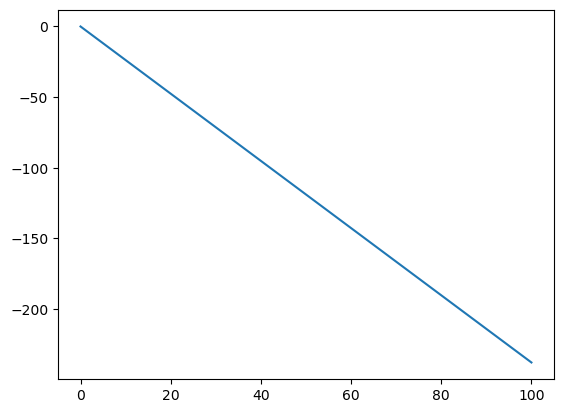

In [98]:
x=np.linspace(0,100,100)
y=dtheta(0)
plt.plot(x,y*x)

In [231]:
from scipy.optimize import brentq
def aim(theta,D=42,alpha=np.radians(27.5), d=6.25, l=16, p=7.5, H=80):
    Y = H-p-l*np.cos(theta+alpha)
    X = np.asarray(D)+d+l*np.sin(theta+alpha)
    return theta - np.arctan2(Y,X)
np.degrees(aim(np.radians(48),90))

16.49279192013196

In [232]:
x,y = [],[]
for D in np.arange(41,121,1):
    x.append(D)
    y.append(np.degrees(brentq(aim,np.radians(20),np.radians(60),args=(D,))))
x=np.array(x)
y=np.array(y)

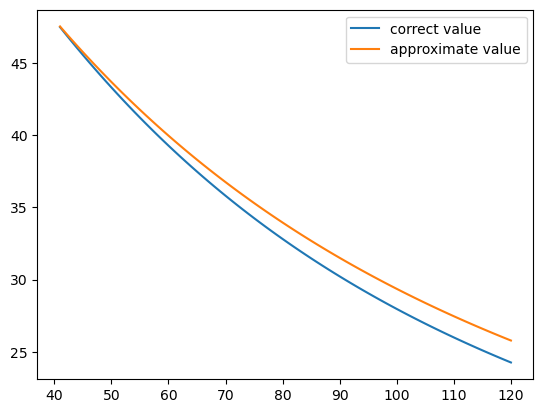

In [233]:
plt.plot(x,y,label='correct value')
plt.plot(x,48-np.degrees(aim(np.radians(48),D=x)),label='approximate value')
plt.legend()


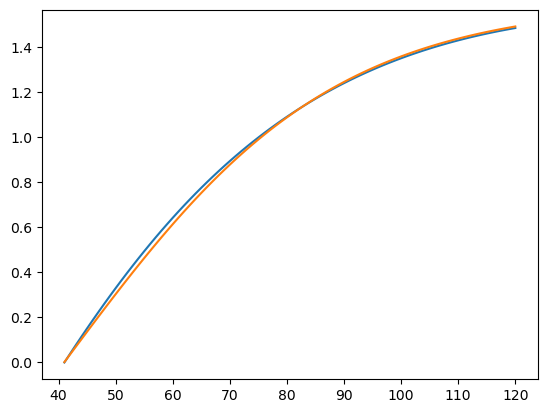

In [191]:
plt.plot(x,48-(y) - np.degrees(aim(np.radians(48),D=(x))))
def f(x):
    return x/2
plt.plot(x,1.6*np.tanh((x-x[0])/47))


In [234]:
48-np.degrees(aim(np.radians(48),D=84))


32.93337747813558

In [227]:
1/np.tan(np.radians([40,38]))


array([1.19175359, 1.27994163])